### Submission 3: Custom CNN from Scratch
### Facial Expression Recognition using CNN on the FER-2013 Dataset

**Course:** CSE366 (Artificial Intelligence)

**Group:** 01

| Name | ID |
|---|---|
| Sumya Kawsar | 2023-3-60-168 |
| Abdullah Al Sami | 2023-2-60-147 |
| Rafid Rahman Sami | 2023-1-60-116 |



## A. Overview
**Goal.** Design and train our own CNN **from scratch** (no pretrained weights) on FER-2013 and evaluate it with the same metrics.

| Requirement | What we do | Section |
|---|---|---|
| Multiple convolutional and pooling layers, ending with a fully connected layer | 4 blocks of (Conv-BN-ReLU) x 2 + MaxPooling, then Flatten > Dense(256) > Dense(7) | C |
| ReLU activations and batch normalization | ReLU after every Conv and Dense layer, BatchNorm after every Conv and the Dense(256) layer | C |
| Proper preprocessing and data augmentation | Cleaned data, pixels scaled to [0, 1], flip / rotation / shift / zoom (training only), class weights | B, C |
| Consistent hyperparameters | Batch 64, Adam, learning rate 1e-3, label smoothing 0.10, one fixed setting table | D |
| Monitor training and validation loss | Loss curves, ReduceLROnPlateau, automatic overfitting / underfitting diagnosis | E, F |
| Early stopping, at least 5 epochs | `EarlyStopping` on validation loss, patience 10, not allowed to stop before epoch 5 | D, E |
| Same metrics as Submission 2 | Accuracy curve, loss curve, classification report, confusion matrix on the test set | E, G |
| Training time and testing time | Training time is measured around `fit`; testing time is measured on the saved best weights, with a warm-up, without retraining | E, G.3 |

## B. Setup and data preparation


In [ ]:
# This cell is only needed on Google Colab. On a local computer (Windows / Jupyter) or Kaggle it is skipped.
try:
    import google.colab          # exists only on Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import os
    # ask for the zip only if the dataset is not already in the session
    if not ((os.path.isdir("train") and os.path.isdir("test")) or os.path.isdir("/content/archive/train")):
        from google.colab import files
        files.upload()   # choose fer2013.zip
        get_ipython().system("unzip -q -o *.zip -d /content")

    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs('/content/drive/MyDrive/fer_sub3', exist_ok=True)
else:
    print("Not running on Google Colab -> upload / Google Drive steps skipped.")


In [1]:
import os
import time
import pickle
import random
import hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# ------------------------- Configuration -------------------------

SEED = 42
BATCH = 64               # batch size
LR = 1e-3                # Adam learning rate
EPOCHS_MAX = 60          # upper limit; early stopping normally stops earlier
MIN_EPOCHS = 5           # early stopping is not allowed to stop before epoch 5
PATIENCE = 10            # stop if validation loss does not improve for 10 epochs
VAL_SPLIT = 0.15
OVERFIT_GAP = 0.15       # train-accuracy minus validation-accuracy above this = overfitting
UNDERFIT_ACC = 0.55      # train and validation accuracy both below this = underfitting
FORCE_RERUN = False      # True = ignore saved results and train again

classes = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
NUM_CLASSES = len(classes)

# ------------------------- Reproducibility -----------------------
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO GPU - training will be slow. Turn on a GPU accelerator.")

# ------------------------- Dataset location ----------------------
DATA_DIR = '/content/archive'

def has_split(d):
    return os.path.isdir(os.path.join(d, 'train')) and os.path.isdir(os.path.join(d, 'test'))

if not has_split(DATA_DIR):                       # fallback: search /kaggle/input
    for root, dirs, _ in os.walk('/kaggle/input'):
        if 'train' in dirs and 'test' in dirs:
            DATA_DIR = root
            break
if not has_split(DATA_DIR) and has_split('.'):    # fallback: current folder
    DATA_DIR = '.'

train_dir = os.path.join(DATA_DIR, 'train')
test_dir = os.path.join(DATA_DIR, 'test')
assert os.path.isdir(train_dir) and os.path.isdir(test_dir), "Could not find train/ and test/ folders!"
print("Using dataset folder:", DATA_DIR)

# Where results and best weights are saved (works on Colab, Kaggle and a local computer)
LEGACY_DIR = "/content/drive/MyDrive/fer_sub3"
if os.path.exists(os.path.join(LEGACY_DIR, "submission3_results.pkl")):
    OUT_DIR = LEGACY_DIR                        # an earlier finished run is found -> it is loaded, not retrained
elif os.path.isdir("/kaggle/working"):
    OUT_DIR = "/kaggle/working"                 # Kaggle
elif os.path.isdir("/content/drive/MyDrive"):
    OUT_DIR = LEGACY_DIR                        # Colab with Google Drive mounted
else:
    OUT_DIR = "fer_sub3"                        # local computer: a normal folder next to the notebook
os.makedirs(OUT_DIR, exist_ok=True)
print("Results folder:", os.path.abspath(OUT_DIR))
RESULTS_PATH = os.path.join(OUT_DIR, "submission3_results.pkl")


TensorFlow: 2.21.0
GPU available: NO GPU - training will be slow. Turn on a GPU accelerator.
Using dataset folder: .


In [2]:
def load_folder(folder):
    images, labels = [], []
    for label, c in enumerate(classes):
        path = os.path.join(folder, c)
        for file in sorted(os.listdir(path)):
            with Image.open(os.path.join(path, file)) as img:
                images.append(np.array(img.convert("L")))
            labels.append(label)
    return np.array(images, dtype=np.uint8), np.array(labels)

x_train, y_train = load_folder(train_dir)
x_test, y_test = load_folder(test_dir)
print("Train:", x_train.shape, " Test:", x_test.shape)

Train: (28709, 48, 48)  Test: (7178, 48, 48)


### B.1 Data cleaning, split and class weights
- **Duplicates:** identical images are kept only once in the training data.
- **Conflicting labels:** if the same image appears with different emotion labels, all copies are removed.
- **Leakage:** test images that also appear in the training set are marked. The official test set stays unchanged (so numbers can be compared with other work) but we also report accuracy on the leak-free part.

In [3]:
md5 = lambda a: hashlib.md5(a.tobytes()).hexdigest()

train_hash = [md5(a) for a in x_train]
labels_by_hash = defaultdict(set)
for h, l in zip(train_hash, y_train):
    labels_by_hash[h].add(int(l))

# --- test images that also appear in the original training set (leakage) ---
test_hash = [md5(a) for a in x_test]
leak_mask = np.array([h in labels_by_hash for h in test_hash])
print(f"Test images that also appear in train (leakage): {leak_mask.sum()} of {len(x_test)} "
      f"({leak_mask.mean()*100:.1f}%)")

# --- clean the training set ---
keep = np.zeros(len(x_train), dtype=bool)
seen = set()
n_conflict = n_dup = 0
for i, h in enumerate(train_hash):
    if len(labels_by_hash[h]) > 1:      # same image, different labels -> drop every copy
        n_conflict += 1
        continue
    if h in seen:                       # exact duplicate -> keep only the first copy
        n_dup += 1
        continue
    seen.add(h)
    keep[i] = True

print(f"Removed {n_dup} duplicate copies and {n_conflict} images with conflicting labels")
x_clean, y_clean = x_train[keep], y_train[keep]
print("Training images before:", len(x_train), "-> after cleaning:", len(x_clean))

# --- stratified train / validation split ---
idx = np.arange(len(x_clean))
tr_idx, va_idx = train_test_split(idx, test_size=VAL_SPLIT, stratify=y_clean, random_state=SEED)
x_tr, y_tr = x_clean[tr_idx], y_clean[tr_idx]
x_val, y_val = x_clean[va_idx], y_clean[va_idx]

# --- class weights (rare classes count more in the loss) ---
cls_counts = np.bincount(y_tr, minlength=NUM_CLASSES)
class_weight = len(y_tr) / (NUM_CLASSES * cls_counts)
sample_w = class_weight[y_tr].astype("float32")

display(pd.DataFrame({
    "class": classes,
    "train": cls_counts,
    "validation": np.bincount(y_val, minlength=NUM_CLASSES),
    "test": np.bincount(y_test, minlength=NUM_CLASSES),
    "class_weight": np.round(class_weight, 3),
}))
print("Train:", x_tr.shape, " Validation:", x_val.shape, " Test:", x_test.shape)

Test images that also appear in train (leakage): 568 of 7178 (7.9%)
Removed 1168 duplicate copies and 107 images with conflicting labels
Training images before: 28709 -> after cleaning: 27434


,class,train,validation,test,class_weight
0,angry,3258,575,958,1.022
1,disgust,322,57,111,10.345
2,fear,3302,583,1024,1.009
3,happy,6022,1063,1774,0.553
4,neutral,4137,730,1233,0.805
5,sad,4008,708,1247,0.831
6,surprise,2269,400,831,1.468


Train: (23318, 48, 48)  Validation: (4116, 48, 48)  Test: (7178, 48, 48)


In [4]:
def make_ds(x, y, weights=None, shuffle=False):
    xs = x.astype("float32")[..., None]            # (N, 48, 48, 1), raw 0-255 (scaling is inside the model)
    ys = tf.one_hot(y, NUM_CLASSES)
    tensors = (xs, ys) if weights is None else (xs, ys, weights)
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if shuffle:
        ds = ds.shuffle(len(xs), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(x_tr, y_tr, weights=sample_w, shuffle=True)   # used for training (class-weighted)
train_eval_ds = make_ds(x_tr, y_tr)                              # same images, no augmentation, for diagnosis
val_ds = make_ds(x_val, y_val)
test_ds = make_ds(x_test, y_test)
print("Datasets ready.")

Datasets ready.


## C. The custom CNN

### C.1 Architecture
Input is the raw 48x48 grayscale face (0-255). Augmentation is active only during training.

| Stage | Layers | Output size |
|---|---|---|
| Input | 48 x 48 x 1 | 48 x 48 x 1 |
| Preprocessing | Augmentation (training only), Rescaling 1/255 | 48 x 48 x 1 |
| Block 1 | 2 x [Conv 3x3, 32 filters, BatchNorm, ReLU] > MaxPool 2x2 > Dropout | 24 x 24 x 32 |
| Block 2 | 2 x [Conv 3x3, 64 filters, BatchNorm, ReLU] > MaxPool 2x2 > Dropout | 12 x 12 x 64 |
| Block 3 | 2 x [Conv 3x3, 128 filters, BatchNorm, ReLU] > MaxPool 2x2 > Dropout | 6 x 6 x 128 |
| Block 4 | 2 x [Conv 3x3, 256 filters, BatchNorm, ReLU] > MaxPool 2x2 > Dropout | 3 x 3 x 256 |
| Classifier | Flatten > Dense(256) > BatchNorm > ReLU > Dropout > **Dense(7, softmax)** | 7 |

**Size.** About 1.77 million parameters in total (the Submission 2 pretrained backbones have 2.3 M for MobileNetV2, 14.7 M for VGG16 and 23.6 M for ResNet50), and no pretrained weights.

**Why this design?**
- Filters double after every pooling (32 > 64 > 128 > 256): early layers find simple edges, later layers combine them into parts such as eyes and mouth.
- Two 3x3 convolutions in a row see a 5x5 area with fewer parameters than one 5x5 convolution (the VGG idea).
- BatchNorm makes training stable and faster. Dropout, augmentation, L2 and label smoothing fight overfitting, which is important because FER-2013 labels are noisy.

### C.2 Regularisation levels 
| Level | Augmentation (rotation / shift / zoom + flip) | Dropout (conv blocks / before output) | L2 on Dense | Label smoothing | Used for |
|---|---|---|---|---|---|
| 1 | 0.08 / 0.10 / 0.10 | 0.25 / 0.5 | 1e-4 | 0.10 | main run |
| 2 | 0.15 / 0.15 / 0.15 | 0.35 / 0.6 | 5e-4 | 0.15 | automatic fix, only if level 1 overfits |

In [5]:
REG = {
    # aug = (rotation, shift, zoom) ; drop_conv = dropout after every conv block ; drop_fc = dropout before the output
    1: dict(aug=(0.08, 0.10, 0.10), drop_conv=0.25, drop_fc=0.5, l2=1e-4, ls=0.10),   # main run (same augmentation as Submission 2)
    2: dict(aug=(0.15, 0.15, 0.15), drop_conv=0.35, drop_fc=0.6, l2=5e-4, ls=0.15),   # stronger fix, used only if level 1 overfits
}
FILTERS = [32, 64, 128, 256]       # number of filters in the 4 convolutional blocks

def augmentation(rot, shift, zoom):
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(rot),
        keras.layers.RandomTranslation(shift, shift),
        keras.layers.RandomZoom(zoom),
    ])

def conv_block(x, filters):
    # two times: Conv 3x3 -> BatchNorm -> ReLU
    for _ in range(2):
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU()(x)
    return x

def build_cnn(level=1):
    reg = REG[level]
    inp = keras.Input(shape=(48, 48, 1))
    x = augmentation(*reg["aug"])(inp)                   # active only during training
    x = keras.layers.Rescaling(1.0 / 255)(x)             # pixels 0-255 -> 0-1

    for f in FILTERS:
        x = conv_block(x, f)
        x = keras.layers.MaxPooling2D(2)(x)
        x = keras.layers.Dropout(reg["drop_conv"])(x)

    x = keras.layers.Flatten()(x)
    x = keras.layers.Dense(256, use_bias=False, kernel_regularizer=keras.regularizers.l2(reg["l2"]))(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU()(x)
    x = keras.layers.Dropout(reg["drop_fc"])(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)    # final fully connected layer
    return keras.Model(inp, out, name="custom_cnn")

keras.backend.clear_session()
_m = build_cnn(1)
_m.summary()
del _m

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,767,207 (6.74 MB)

 Trainable params: 1,764,775 (6.73 MB)

 Non-trainable params: 2,432 (9.50 KB)

## D. Training setup (the same for every run)

| Hyperparameter | Value |
|---|---|
| Optimizer | Adam, learning rate 1e-3 |
| Batch size | 64 |
| Loss | Categorical cross-entropy with label smoothing, **class weights** for the imbalance |
| Maximum epochs | 60 |
| **Early stopping** | monitor = validation loss, patience = 10, **starts only after epoch 5** (so at least 5 epochs are always trained), best weights restored |
| Learning-rate schedule | `ReduceLROnPlateau`: learning rate x 0.5 when validation loss does not improve for 4 epochs |
| Best model | weights of the epoch with the lowest validation loss |
| Seed | 42 |

**Overfitting / underfitting diagnosis (automatic).** After training, we reload the best weights and measure accuracy on the training images **without augmentation or dropout**, on the validation set and on the test set. Train accuracy minus validation accuracy above 0.15 = overfitting. Both accuracies below 0.55 = underfitting.

In [6]:
RESULTS = {}
if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        RESULTS = pickle.load(f)
    print("Loaded earlier results:", list(RESULTS.keys()))

def diagnose(train_acc, val_acc):
    gap = train_acc - val_acc
    if gap > OVERFIT_GAP:
        return "overfitting"
    if train_acc < UNDERFIT_ACC and val_acc < UNDERFIT_ACC:
        return "underfitting"
    return "good fit"

NAME = "CNN"

def run_experiment(level=1):
    key = f"{NAME}|L{level}"
    TITLE = f"Custom CNN from scratch (regularisation level {level})"
    if key in RESULTS:
        print(f"[skip] {key} already finished (loaded from file)")
        return RESULTS[key]

    print(f"\n{'='*70}\n{TITLE}\n{'='*70}")
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_cnn(level)
    loss = keras.losses.CategoricalCrossentropy(label_smoothing=REG[level]["ls"])
    model.compile(optimizer=keras.optimizers.Adam(LR), loss=loss, metrics=["accuracy"])
    ckpt = os.path.join(OUT_DIR, f"{key.replace('|', '_').replace('+', 'plus')}.weights.h5")
    callbacks = [
        # saves the weights of the epoch with the lowest validation loss
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", mode="min",
                                        save_best_only=True, save_weights_only=True),
        # lowers the learning rate when validation loss stalls
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
        # early stopping: only active after MIN_EPOCHS, so training lasts at least 5 epochs
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, start_from_epoch=MIN_EPOCHS,
                                      restore_best_weights=True, verbose=1),
    ]

    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_MAX, callbacks=callbacks, verbose=2)
    minutes = (time.time() - t0) / 60
    hist = {k: [float(v) for v in h.history[k]] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}

    model.load_weights(ckpt)                               # go back to the best epoch
    train_loss, train_acc = model.evaluate(train_eval_ds, verbose=0)   # train images WITHOUT augmentation / dropout
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    val_probs = model.predict(val_ds, verbose=0)
    test_probs = model.predict(test_ds, verbose=0)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))

    yp = test_probs.argmax(1)
    res = dict(
        key=key, name=NAME, title=TITLE, level=level, history=hist,
        epochs_run=len(hist["loss"]), best_epoch=int(np.argmin(hist["val_loss"])) + 1,
        minutes=minutes, trainable_params=trainable,
        train_loss=float(train_loss), train_acc=float(train_acc),
        val_loss=float(val_loss), val_acc=float(val_acc),
        val_macro_f1=float(f1_score(y_val, val_probs.argmax(1), average="macro")),
        test_probs=test_probs,
        test_acc=float(accuracy_score(y_test, yp)),
        clean_test_acc=float(accuracy_score(y_test[~leak_mask], yp[~leak_mask])),
        macro_f1=float(f1_score(y_test, yp, average="macro")),
        weighted_f1=float(f1_score(y_test, yp, average="weighted")),
    )
    res["gap"] = res["train_acc"] - res["val_acc"]
    res["diagnosis"] = diagnose(res["train_acc"], res["val_acc"])

    RESULTS[key] = res
    with open(RESULTS_PATH, "wb") as f:
        pickle.dump(RESULTS, f)
    print(f"Finished in {minutes:.1f} min | epochs run {res['epochs_run']} (max {EPOCHS_MAX}) | "
          f"best epoch {res['best_epoch']} | train {res['train_acc']:.3f} | val {res['val_acc']:.3f} | "
          f"test {res['test_acc']:.3f} | {res['diagnosis']}")
    return res


Loaded earlier results: ['CNN|L1']


In [7]:
def show_run(res, note=""):
    # accuracy curve + loss curve (train vs validation)
    h = res["history"]
    ep = np.arange(1, len(h["accuracy"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    for a, (tr, va, ylabel) in zip(ax, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
        a.plot(ep, h[tr], label="train", lw=2)
        a.plot(ep, h[va], label="validation", lw=2)
        a.axvline(res["best_epoch"], color="green", ls=":", label=f"best epoch ({res['best_epoch']})")
        a.set_xlabel("Epoch")
        a.set_ylabel(ylabel)
        a.set_title(f"{ylabel} curve")
        a.grid(alpha=0.3)
        a.legend()
    plt.suptitle(f"{res['title']}{note}")
    plt.tight_layout()
    plt.show()

def show_report(probs, title):
    # classification report + confusion matrix on the TEST set
    y_pred = probs.argmax(1)
    print(f"\n{title}")
    print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, target_names=classes, digits=3, zero_division=0))
    cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
    ax[0].set_title("Confusion matrix (counts)")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes,
                ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title("Confusion matrix (each row = 100% of that true class)")
    for a in ax:
        a.set_xlabel("Predicted")
        a.set_ylabel("True")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


## E. Training the custom CNN
Training stops automatically when the validation loss has not improved for 10 epochs (after epoch 5). The green dotted line marks the best epoch, whose weights are used for all results.

> The *train* curves are measured **with** augmentation and dropout, so they can look lower than the validation curves. This is normal. The fair train accuracy (no augmentation) is measured separately in Section F.

[skip] CNN|L1 already finished (loaded from file)


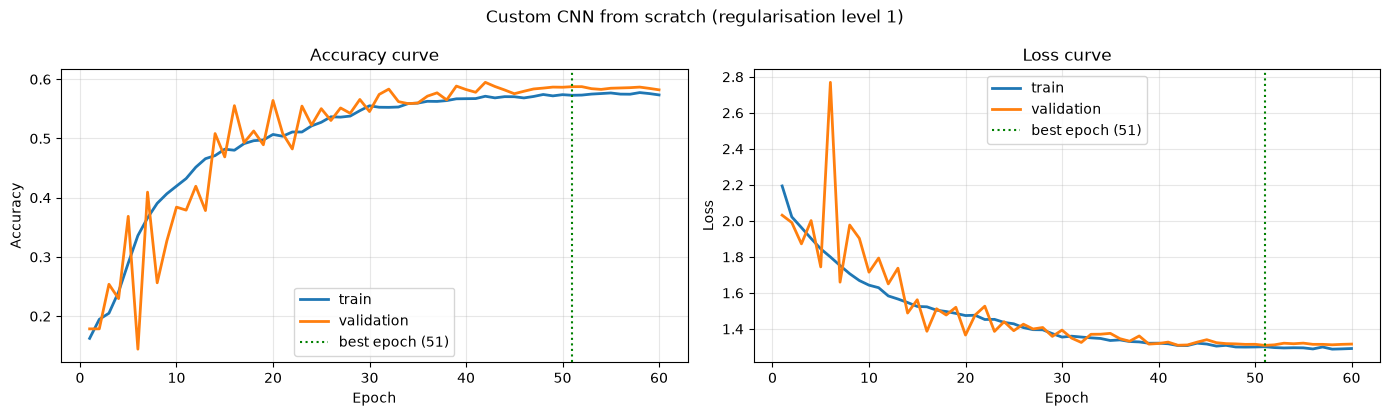

Epochs trained: 60  (minimum required: 5, maximum allowed: 60)
Training ran up to the maximum number of epochs (early stopping did not end it sooner).


In [8]:
r1 = run_experiment(level=1)
show_run(r1)
print(f"Epochs trained: {r1['epochs_run']}  (minimum required: {MIN_EPOCHS}, maximum allowed: {EPOCHS_MAX})")
assert r1["epochs_run"] >= MIN_EPOCHS, "Early stopping stopped too early!"
if r1["epochs_run"] < EPOCHS_MAX:
    print(f"Early stopping ended training at epoch {r1['epochs_run']}; best epoch was {r1['best_epoch']}.")
else:
    print("Training ran up to the maximum number of epochs (early stopping did not end it sooner).")

## F. Overfitting and underfitting: diagnosis and fix
### F.1 Diagnosis

In [9]:
display(pd.DataFrame([{
    "Run": r1["title"], "Epochs run": r1["epochs_run"], "Best epoch": r1["best_epoch"],
    "Train loss": r1["train_loss"], "Val loss": r1["val_loss"],
    "Train acc": r1["train_acc"], "Val acc": r1["val_acc"], "Gap (train - val)": r1["gap"],
    "Diagnosis": r1["diagnosis"],
}]).round(3))
print(f"\nEpochs run: {r1['epochs_run']} of max {EPOCHS_MAX} | best epoch: {r1['best_epoch']}")
if r1["epochs_run"] >= EPOCHS_MAX:
    print("NOTE: training used all allowed epochs, so early stopping did not end it. "
          "If the best epoch is close to the last epoch, the model may still have been improving. "
          "Set EPOCHS_MAX higher (for example 100) and FORCE_RERUN = True to let early stopping decide when to stop.")
else:
    print(f"Early stopping ended training {r1['epochs_run'] - r1['best_epoch']} epochs after the best epoch.")


,Run,Epochs run,Best epoch,Train loss,Val loss,Train acc,Val acc,Gap (train - val),Diagnosis
0,Custom CNN from scratch (regularisation level 1),60,51,1.271,1.309,0.607,0.587,0.019,good fit


### F.2 Applying the fix


In [10]:
def get_final():
    # the better of level 1 / level 2 according to VALIDATION accuracy
    cands = [r for r in RESULTS.values() if r["name"] == NAME]
    return max(cands, key=lambda r: r["val_acc"])

if r1["diagnosis"] == "overfitting":
    print(f">>> OVERFITTING (gap {r1['gap']:+.3f}). Training again with stronger regularisation (level 2)...")
    r2 = run_experiment(level=2)
    show_run(r2, note=" - after overfitting fix")
    kept = "level 2 (fixed)" if r2["val_acc"] > r1["val_acc"] else "level 1 (original)"
    display(pd.DataFrame([
        {"Version": "Level 1", "Train acc": r1["train_acc"], "Val acc": r1["val_acc"], "Gap": r1["gap"], "Val loss": r1["val_loss"], "Test acc": r1["test_acc"]},
        {"Version": "Level 2 (fix)", "Train acc": r2["train_acc"], "Val acc": r2["val_acc"], "Gap": r2["gap"], "Val loss": r2["val_loss"], "Test acc": r2["test_acc"]},
    ]).round(3))
    print("Kept (by validation accuracy):", kept)
elif r1["diagnosis"] == "underfitting":
    print(f">>> UNDERFITTING (train {r1['train_acc']:.3f}, val {r1['val_acc']:.3f}). Increase FILTERS or PATIENCE and run again.")
else:
    print(f"Good fit: gap {r1['gap']:+.3f} is below {OVERFIT_GAP}. No extra fix needed.")

final = get_final()
print(f"\nFinal model for evaluation: {final['title']}")

Good fit: gap +0.019 is below 0.15. No extra fix needed.

Final model for evaluation: Custom CNN from scratch (regularisation level 1)


## G. Final evaluation on the test set
### G.1 Curves, classification report and confusion matrix

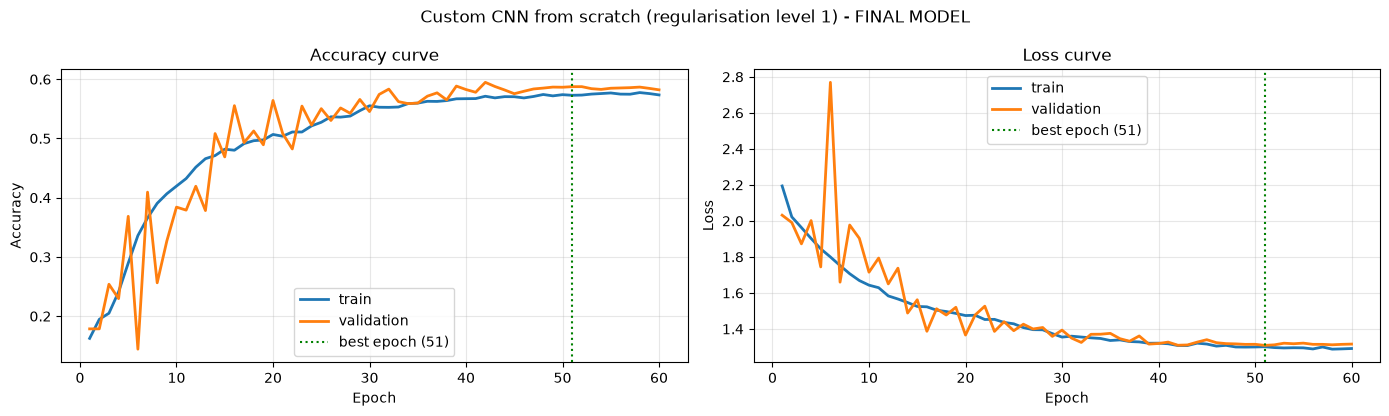


Final model: Custom CNN from scratch (regularisation level 1)
Test accuracy: 0.5864
              precision    recall  f1-score   support

       angry      0.480     0.497     0.488       958
     disgust      0.252     0.676     0.367       111
        fear      0.410     0.339     0.371      1024
       happy      0.893     0.766     0.825      1774
     neutral      0.522     0.657     0.582      1233
         sad      0.507     0.387     0.439      1247
    surprise      0.649     0.793     0.714       831

    accuracy                          0.586      7178
   macro avg      0.530     0.588     0.541      7178
weighted avg      0.600     0.586     0.586      7178



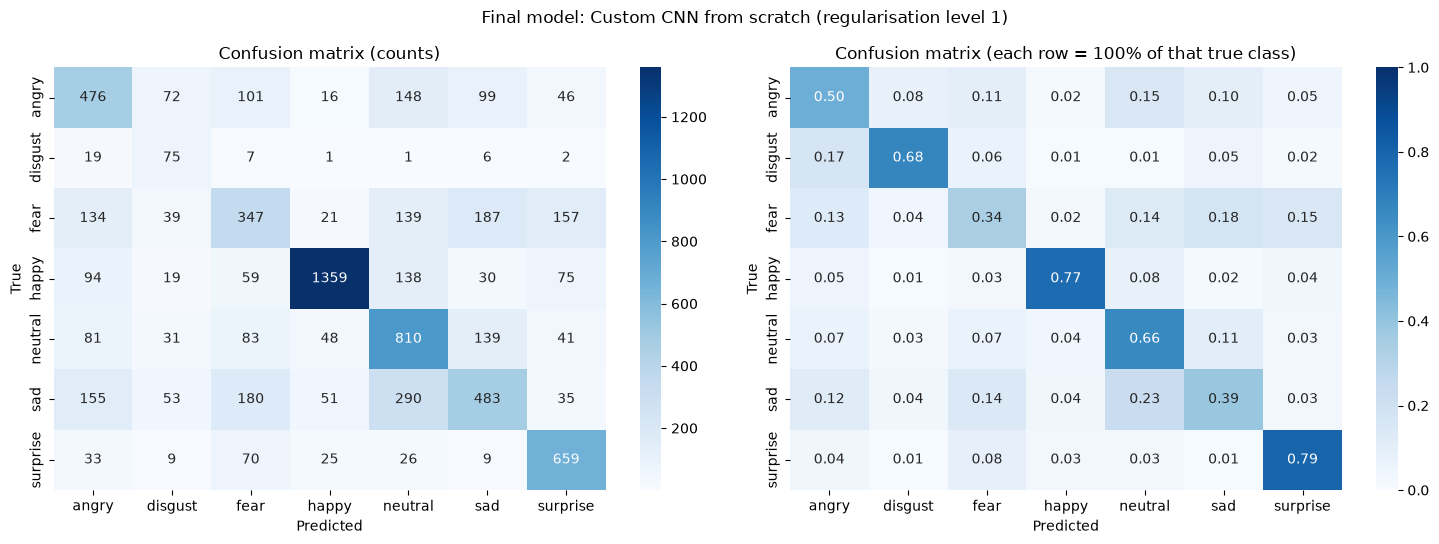

Test accuracy (official test set)  : 0.5864
Test accuracy (leak-free part only): 0.5716  (6610 images)
Macro-F1: 0.5408 | Weighted-F1: 0.5865


In [11]:
show_run(final, note=" - FINAL MODEL")
show_report(final["test_probs"], f"Final model: {final['title']}")
print(f"Test accuracy (official test set)  : {final['test_acc']:.4f}")
print(f"Test accuracy (leak-free part only): {final['clean_test_acc']:.4f}  ({(~leak_mask).sum()} images)")
print(f"Macro-F1: {final['macro_f1']:.4f} | Weighted-F1: {final['weighted_f1']:.4f}")

### G.2 Per-class F1 and examples of mistakes

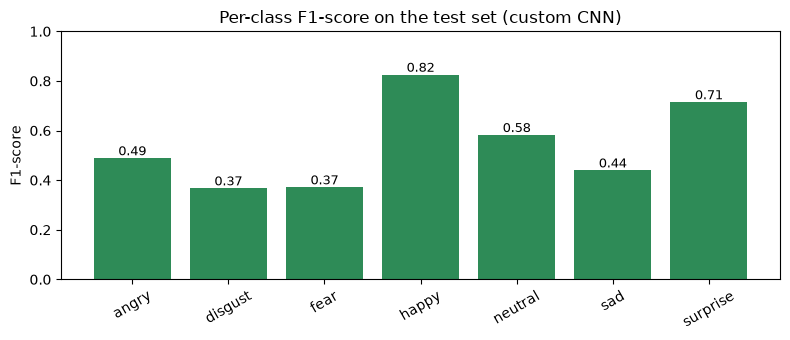

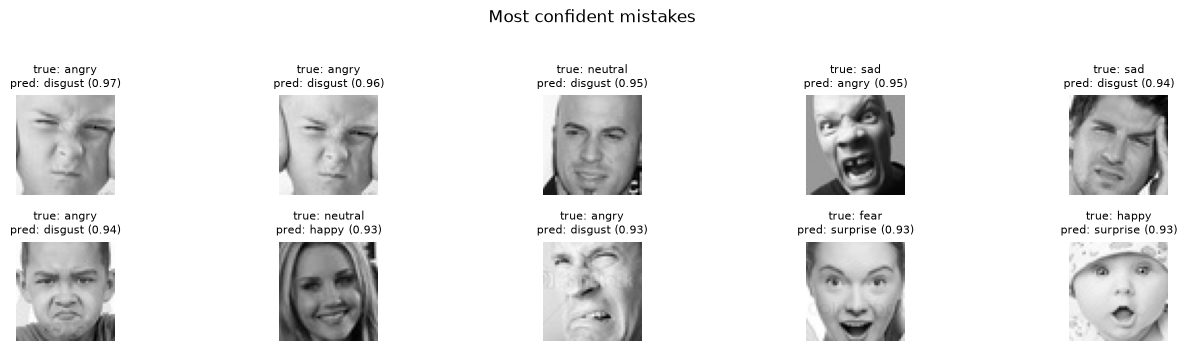

In [ ]:
y_pred = final["test_probs"].argmax(1)
f1_per_class = f1_score(y_test, y_pred, average=None, labels=range(NUM_CLASSES))

plt.figure(figsize=(8, 3.5))
bars = plt.bar(classes, f1_per_class, color="seagreen")
plt.bar_label(bars, fmt="%.2f", fontsize=9)
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("Per-class F1-score on the test set (custom CNN)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 10 wrongly classified test images (the model was most confident)
wrong = np.where(y_pred != y_test)[0]
conf = final["test_probs"].max(1)[wrong]
show_idx = wrong[np.argsort(-conf)[:10]]
plt.figure(figsize=(14, 3.4))
for k, i in enumerate(show_idx):
    plt.subplot(2, 5, k + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"true: {classes[y_test[i]]}\npred: {classes[y_pred[i]]} ({conf[np.argsort(-conf)[k]]:.2f})", fontsize=8)
    plt.axis("off")
plt.suptitle("Most confident mistakes", y=1.02)
plt.tight_layout()
plt.show()

### G.3 Testing time (inference time on the test set)
Training time was already measured around `model.fit`. Here we measure the **testing time**: how long the trained model needs to predict the 7,178 test images.

How it is measured (no retraining):
1. The same architecture is rebuilt with `build_cnn` and the **saved best weights** (lowest validation loss) are loaded from disk.
2. One **warm-up** prediction pass over the test images is run first and is **not** timed. The first call of `predict` is always slower (TensorFlow builds its graph and allocates memory), which would make the result unfair. The warm-up only predicts; nothing is trained or changed.
3. `model.predict` on the whole test set is timed with `time.perf_counter()` (from the `time` module). Timing is repeated 3 times and the **mean** is reported, because timings on a normal computer fluctuate a little.
4. The test set is only used for prediction here. It is not used for training, validation, early stopping or choosing the best model.

The measured time covers batching and prediction of the 7,178 test images already stored in memory. It does not include reading the image files from disk or computing the metrics.

In [ ]:
import json

N_TIMED_RUNS = 3            # the test set is predicted 3 times; the mean time is reported

ckpt_path = os.path.join(OUT_DIR, f"{final['key'].replace('|', '_').replace('+', 'plus')}.weights.h5")
if not os.path.exists(ckpt_path):
    raise FileNotFoundError(
        f"Best-weights file not found: {ckpt_path}\n"
        f"Files found in {OUT_DIR}: {os.listdir(OUT_DIR) if os.path.isdir(OUT_DIR) else 'folder does not exist'}")

keras.backend.clear_session()                   # same start as in run_experiment, so layer names match
timing_model = build_cnn(final["level"])
timing_model.load_weights(ckpt_path)            # weights of the epoch with the lowest validation loss
print("Loaded best weights from:", ckpt_path)

#  The test set is used only for prediction
n_test = len(x_test)
assert test_ds.cardinality().numpy() == int(np.ceil(n_test / BATCH)), "test_ds does not match x_test"
print(f"Test images to predict: {n_test}  (training images: {len(x_tr)}, validation images: {len(x_val)})")

# One full prediction pass, exactly like the timed one (prediction only, no training)
_ = timing_model.predict(test_ds, verbose=0)

#  Timed prediction on the whole test set
run_seconds = []
for run in range(N_TIMED_RUNS):
    t_start = time.perf_counter()
    timed_probs = timing_model.predict(test_ds, verbose=0)
    t_end = time.perf_counter()
    run_seconds.append(t_end - t_start)
    print(f"  run {run + 1}: {run_seconds[-1]:.2f} s")

total_sec = float(np.mean(run_seconds))
total_min = total_sec / 60
ms_per_image = total_sec * 1000 / n_test

print(f"\nTotal testing time (mean of {N_TIMED_RUNS} runs): {total_sec:.2f} seconds = {total_min:.3f} minutes")
print(f"Average inference time per image: {ms_per_image:.3f} ms  ({n_test / total_sec:.0f} images per second)")

# The reloaded model must give the same predictions as the original evaluation
same_pred = (timed_probs.argmax(1) == final["test_probs"].argmax(1)).mean()
print(f"Predictions identical to the original evaluation: {same_pred * 100:.2f}% of test images "
      f"(test accuracy now {accuracy_score(y_test, timed_probs.argmax(1)):.4f} vs saved {final['test_acc']:.4f})")
if same_pred < 0.999:
    print("WARNING: the loaded weights do not reproduce the saved test predictions. Check the weights file above.")


test_timing = dict(total_sec=total_sec, total_min=total_min, ms_per_image=ms_per_image,
                   n_images=int(n_test), runs_sec=[float(v) for v in run_seconds],
                   hardware=("CPU" if not tf.config.list_physical_devices("GPU") else "GPU"))
with open(os.path.join(OUT_DIR, "submission3_testing_time.json"), "w") as f:
    json.dump(test_timing, f, indent=2)
print("Saved:", os.path.join(OUT_DIR, "submission3_testing_time.json"))

Loaded best weights from: /content/drive/MyDrive/fer_sub3\CNN_L1.weights.h5
Test images to predict: 7178  (training images: 23318, validation images: 4116)
  run 1: 8.38 s
  run 2: 8.37 s
  run 3: 8.73 s

Total testing time (mean of 3 runs): 8.49 seconds = 0.142 minutes
Average inference time per image: 1.183 ms  (845 images per second)
Predictions identical to the original evaluation: 100.00% of test images (test accuracy now 0.5864 vs saved 0.5864)
Saved: /content/drive/MyDrive/fer_sub3\submission3_testing_time.json


### G.4 Findings generated from our own results
Same idea as Submission 2 (Section G.1): the text below is produced from the numbers, so it always matches the results above.

In [ ]:
from sklearn.metrics import precision_score, recall_score

y_pred = final["test_probs"].argmax(1)
f1c = f1_score(y_test, y_pred, average=None, labels=range(NUM_CLASSES))
prec_c = precision_score(y_test, y_pred, average=None, labels=range(NUM_CLASSES), zero_division=0)
rec_c = recall_score(y_test, y_pred, average=None, labels=range(NUM_CLASSES), zero_division=0)

print(f"1. Test accuracy {final['test_acc']:.3f}, macro-F1 {final['macro_f1']:.3f}. "
      f"On the leak-free test images the accuracy is {final['clean_test_acc']:.3f} "
      f"({(final['test_acc'] - final['clean_test_acc']) * 100:+.1f} points lower than on the official test set).")
print(f"2. Easiest emotion: {classes[int(np.argmax(f1c))]} (F1 {f1c.max():.2f}). "
      f"Hardest emotion: {classes[int(np.argmin(f1c))]} (F1 {f1c.min():.2f}).")

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES)).astype(float)
cm = cm / cm.sum(axis=1, keepdims=True)
np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], classes[i], classes[j]) for i in range(NUM_CLASSES)
                for j in range(NUM_CLASSES) if i != j), reverse=True)[:3]
print("3. Most confused pairs (share of the true class predicted as the other class):")
for v, t, p in pairs:
    print(f"   {t} -> {p}: {v * 100:.1f}%")

d = classes.index("disgust")
if rec_c[d] > prec_c[d]:
    print(f"4. Disgust: recall {rec_c[d]:.2f} but precision {prec_c[d]:.2f}. The class weights make the model "
          "predict disgust often (it finds most real disgust faces) but many of those predictions are wrong.")
else:
    print(f"4. Disgust: precision {prec_c[d]:.2f}, recall {rec_c[d]:.2f}. The rare class is still hard even with class weights.")

## H. Comparison with the pretrained models from Submission 2


### H.1 What is compared, and where the Submission 2 numbers come from
All numbers are **test-set results** of the **official test set** (7,178 images, never used for training or validation). Validation accuracy is not used in the comparison table.

| | Submission 2 (pretrained) | Submission 3 (custom CNN) |
|---|---|---|
| Same data | same cleaned training data, same stratified 85/15 split, same official test set | same |
| Metric code | `accuracy_score`, `f1_score(average="macro" / "weighted")`, macro precision / recall as in `classification_report` | the same functions |
| Input | 48x48 gray face, resized to 96x96 and copied to 3 channels (ImageNet normalisation) | raw 48x48 gray face, scaled to 0-1 |
| Training length | fixed 30 epochs (fine-tuned: 5 warm-up + 25 epochs) | up to 60 epochs, early stopping on validation loss |
| Best weights chosen by | highest validation **accuracy** | lowest validation **loss** |
| Training time | measured around `fit` | measured around `fit` |
| Testing time | **not measured in Submission 2** -> shown as unavailable | measured in G.3 |



In [ ]:
# Comparison table: Submission 2 (pretrained) vs Submission 3 (custom CNN) ----------------
from sklearn.metrics import precision_score, recall_score

NA = np.nan   # "unavailable" (shown as N/A in the table, never replaced by an estimate)


S2_PKL_CANDIDATES = [
    os.path.join(os.path.dirname(OUT_DIR), "fer_sub2", "submission2_results.pkl"),   # same place as fer_sub3
    os.path.join("fer_sub2", "submission2_results.pkl"),
    "submission2_results.pkl",
    "/content/drive/MyDrive/fer_sub2/submission2_results.pkl",    # Colab + Drive
    "/kaggle/working/submission2_results.pkl",                    # Kaggle
]
S2_PKL = next((p for p in S2_PKL_CANDIDATES if os.path.exists(p)), None)


S2_PRINTED = {
    # (model, mode):  acc,   leak-free, macro P, macro R, macro F1, weighted F1, train min
    ("VGG16",       "frozen"):   (0.405, 0.402, NA,    NA,    0.339, 0.382, 11.598),
    ("VGG16",       "finetune"): (0.617, 0.606, NA,    NA,    0.598, 0.615, 30.421),
    ("ResNet50",    "frozen"):   (0.462, 0.449, 0.410, 0.440, 0.405, 0.453, 12.749),
    ("ResNet50",    "finetune"): (0.646, 0.630, 0.632, 0.646, 0.638, 0.648, 43.428),
    ("MobileNetV2", "frozen"):   (0.395, 0.389, 0.358, 0.353, 0.338, 0.377, 5.504),
    ("MobileNetV2", "finetune"): (0.608, 0.595, 0.587, 0.575, 0.578, 0.609, 21.991),
}

def metrics_from_probs(probs):
    yp = probs.argmax(1)
    return dict(acc=accuracy_score(y_test, yp),
                clean_acc=accuracy_score(y_test[~leak_mask], yp[~leak_mask]),
                p=precision_score(y_test, yp, average="macro", zero_division=0),
                r=recall_score(y_test, yp, average="macro", zero_division=0),
                f1=f1_score(y_test, yp, average="macro"),
                wf1=f1_score(y_test, yp, average="weighted"))

rows = []
MODE_TXT = {"frozen": "Frozen backbone (no fine-tuning)", "finetune": "Fine-tuned (whole backbone)"}

# ---- Submission 2 rows
if S2_PKL:
    with open(S2_PKL, "rb") as f:
        S2 = pickle.load(f)
    S2_SOURCE = f"recomputed from the saved test predictions in {S2_PKL}"
else:
    S2 = None
    S2_SOURCE = "numbers printed in the saved outputs of Submission2.ipynb (submission2_results.pkl was not found)"

for name in ["VGG16", "ResNet50", "MobileNetV2"]:
    for mode in ["frozen", "finetune"]:
        if S2 is not None:
            cands = [r for r in S2.values() if r["name"] == name and r["mode"] == mode and r["level"] in (1, 2)]
            r = max(cands, key=lambda r: r["val_acc"])          # same rule as Submission 2 (validation, not test)
            m = metrics_from_probs(r["test_probs"])
            train_min = r["minutes"]
        else:
            a, ca, p, rc, f1v, wf1, train_min = S2_PRINTED[(name, mode)]
            m = dict(acc=a, clean_acc=ca, p=p, r=rc, f1=f1v, wf1=wf1)
        rows.append({"Model": name, "Model type": "Pretrained (ImageNet)", "Fine-tuning mode": MODE_TXT[mode],
                     "Test accuracy": m["acc"], "Macro precision": m["p"], "Macro recall": m["r"],
                     "Macro F1": m["f1"], "Weighted F1": m["wf1"],
                     "Training time (min)": train_min,
                     "Testing time (s)": NA, "Inference per image (ms)": NA,     # not measured in Submission 2
                     "Leak-free test accuracy": m["clean_acc"]})

# ---- Submission 3 row (metrics from the original saved test predictions of the final model)
m3 = metrics_from_probs(final["test_probs"])
t3 = globals().get("test_timing")        # created by the G.3 cell
rows.append({"Model": "Custom CNN (scratch)", "Model type": "Custom CNN (from scratch)",
             "Fine-tuning mode": "Not applicable (no pretrained weights)",
             "Test accuracy": m3["acc"], "Macro precision": m3["p"], "Macro recall": m3["r"],
             "Macro F1": m3["f1"], "Weighted F1": m3["wf1"],
             "Training time (min)": final["minutes"],
             "Testing time (s)": t3["total_sec"] if t3 else NA,
             "Inference per image (ms)": t3["ms_per_image"] if t3 else NA,
             "Leak-free test accuracy": m3["clean_acc"]})
if not t3:
    print("NOTE: run the G.3 cell first to fill in the custom CNN testing time.")

cmp_df = pd.DataFrame(rows)
print("Submission 2 source:", S2_SOURCE)
print("Metrics are computed on the official test set (7178 images); N/A = not available, nothing is estimated.\n")

main_cols = ["Model", "Model type", "Fine-tuning mode", "Test accuracy", "Macro precision", "Macro recall",
             "Macro F1", "Weighted F1", "Training time (min)", "Testing time (s)", "Inference per image (ms)"]

def nice(df, formats):
    # turns numbers into text with fixed decimals; missing values (NaN) become "N/A"  
    out = df.copy()
    for col, fmt in formats.items():
        out[col] = out[col].apply(lambda v: "N/A" if pd.isna(v) else fmt.format(v))
    out.index = range(1, len(out) + 1)
    return out

formats = {c: "{:.3f}" for c in main_cols[3:9]}
formats.update({"Training time (min)": "{:.1f}", "Testing time (s)": "{:.2f}", "Inference per image (ms)": "{:.3f}"})
display(nice(cmp_df[main_cols], formats))

print("\nLeak-free subset (6610 test images that do not appear in the training set) - a different, smaller test subset:")
leak_df = cmp_df[["Model", "Test accuracy", "Leak-free test accuracy"]].rename(
    columns={"Test accuracy": "Official test accuracy (7178 images)",
             "Leak-free test accuracy": "Leak-free subset accuracy (6610 images)"})
display(nice(leak_df, {"Official test accuracy (7178 images)": "{:.3f}",
                       "Leak-free subset accuracy (6610 images)": "{:.3f}"}))

cmp_df.to_csv(os.path.join(OUT_DIR, "submission2_vs_submission3_comparison.csv"), index=False)

Submission 2 source: numbers printed in the saved outputs of Submission2.ipynb (submission2_results.pkl was not found)
Metrics are computed on the official test set (7178 images); N/A = not available, nothing is estimated.



,Model,Model type,Fine-tuning mode,Test accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Training time (min),Testing time (s),Inference per image (ms)
1,VGG16,Pretrained (ImageNet),Frozen backbone (no fine-tuning),0.405,N/A,N/A,0.339,0.382,11.6,N/A,N/A
2,VGG16,Pretrained (ImageNet),Fine-tuned (whole backbone),0.617,N/A,N/A,0.598,0.615,30.4,N/A,N/A
3,ResNet50,Pretrained (ImageNet),Frozen backbone (no fine-tuning),0.462,0.410,0.440,0.405,0.453,12.7,N/A,N/A
4,ResNet50,Pretrained (ImageNet),Fine-tuned (whole backbone),0.646,0.632,0.646,0.638,0.648,43.4,N/A,N/A
5,MobileNetV2,Pretrained (ImageNet),Frozen backbone (no fine-tuning),0.395,0.358,0.353,0.338,0.377,5.5,N/A,N/A
6,MobileNetV2,Pretrained (ImageNet),Fine-tuned (whole backbone),0.608,0.587,0.575,0.578,0.609,22.0,N/A,N/A
7,Custom CNN (scratch),Custom CNN (from scratch),Not applicable (no pretrained weights),0.586,0.530,0.588,0.541,0.586,127.0,8.49,1.183



Leak-free subset (6610 test images that do not appear in the training set) - a different, smaller test subset:


,Model,Official test accuracy (7178 images),Leak-free subset accuracy (6610 images)
1,VGG16,0.405,0.402
2,VGG16,0.617,0.606
3,ResNet50,0.462,0.449
4,ResNet50,0.646,0.630
5,MobileNetV2,0.395,0.389
6,MobileNetV2,0.608,0.595
7,Custom CNN (scratch),0.586,0.572


### H.2 Charts

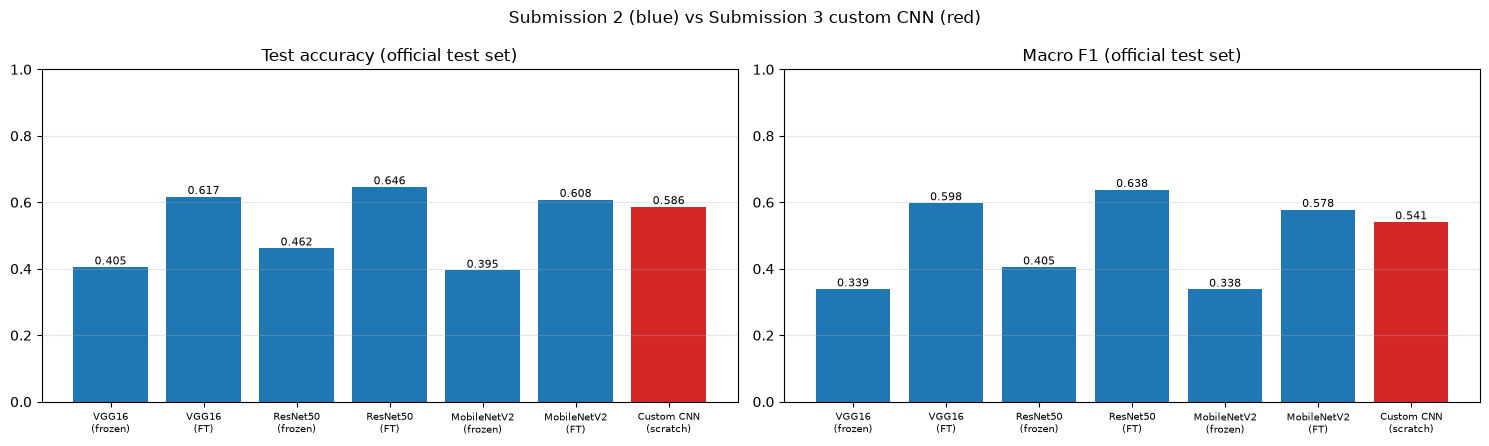

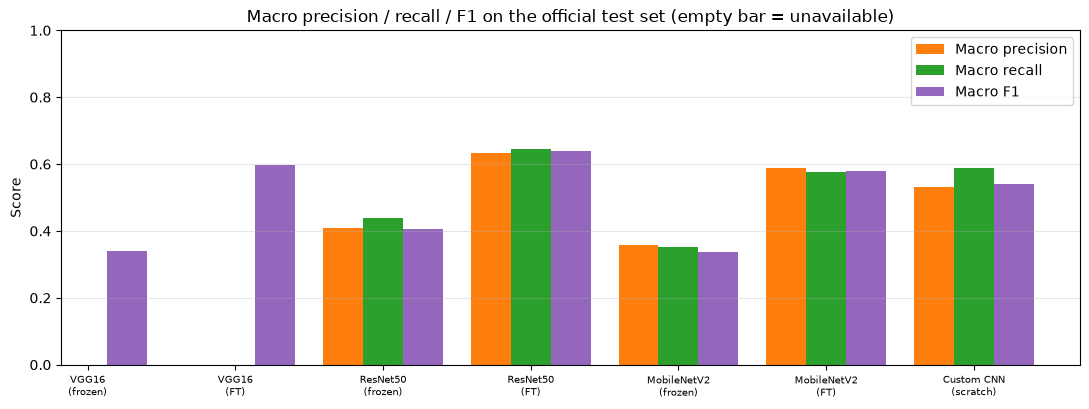

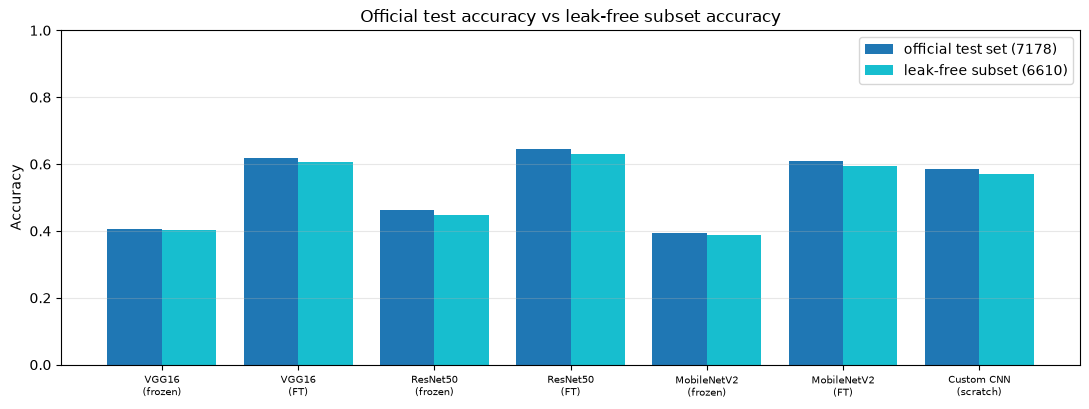

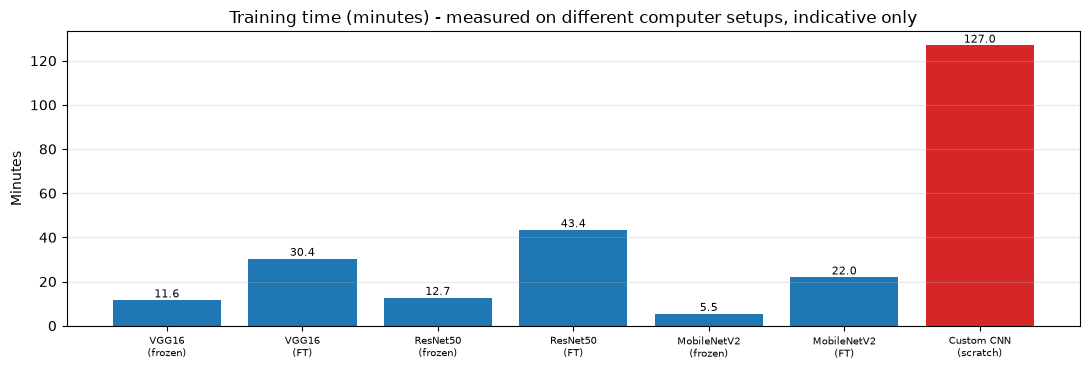

In [ ]:
# ----------------  Charts ----------------
labels = [f"{m}\n({'FT' if 'Fine' in md else 'frozen'})" if t.startswith("Pretrained") else "Custom CNN\n(scratch)"
          for m, md, t in zip(cmp_df["Model"], cmp_df["Fine-tuning mode"], cmp_df["Model type"])]
colors = ["tab:blue" if t.startswith("Pretrained") else "tab:red" for t in cmp_df["Model type"]]

# Chart 1: test accuracy and macro-F1 (official test set)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, col in zip(ax, ["Test accuracy", "Macro F1"]):
    bars = a.bar(labels, cmp_df[col], color=colors)
    a.bar_label(bars, fmt="%.3f", fontsize=8)
    a.set_ylim(0, 1)
    a.set_title(f"{col} (official test set)")
    a.tick_params(axis="x", labelsize=7)
    a.grid(axis="y", alpha=0.3)
plt.suptitle("Submission 2 (blue) vs Submission 3 custom CNN (red)")
plt.tight_layout()
plt.show()

# Chart 2: macro precision, macro recall, macro F1 side by side (a missing value stays an empty gap)
x = np.arange(len(cmp_df)); w = 0.27
plt.figure(figsize=(11, 4.2))
for k, (col, c) in enumerate([("Macro precision", "tab:orange"), ("Macro recall", "tab:green"), ("Macro F1", "tab:purple")]):
    plt.bar(x + (k - 1) * w, cmp_df[col], w, label=col, color=c)
plt.xticks(x, labels, fontsize=7)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Macro precision / recall / F1 on the official test set (empty bar = unavailable)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 3: official test accuracy vs leak-free subset accuracy (two different test sets)
plt.figure(figsize=(11, 4.2))
plt.bar(x - 0.2, cmp_df["Test accuracy"], 0.4, label="official test set (7178)", color="tab:blue")
plt.bar(x + 0.2, cmp_df["Leak-free test accuracy"], 0.4, label="leak-free subset (6610)", color="tab:cyan")
plt.xticks(x, labels, fontsize=7)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Official test accuracy vs leak-free subset accuracy")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(11, 3.8))
bars = plt.bar(labels, cmp_df["Training time (min)"], color=colors)
plt.bar_label(bars, fmt="%.1f", fontsize=8)
plt.ylabel("Minutes")
plt.title("Training time (minutes) - measured on different computer setups, indicative only")
plt.xticks(fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### H.3 Interpretation

In [ ]:
# ---------------- Interpretation (generated from the table above) ----------------
best_f1 = cmp_df.loc[cmp_df["Macro F1"].idxmax()]
best_acc = cmp_df.loc[cmp_df["Test accuracy"].idxmax()]
cnn = cmp_df[cmp_df["Model type"].str.startswith("Custom")].iloc[0]
pre = cmp_df[cmp_df["Model type"].str.startswith("Pretrained")]

def tag(r):
    return f"{r['Model']} ({r['Fine-tuning mode']})" if r["Model type"].startswith("Pretrained") else r["Model"]

print(f"1. Best test Macro F1 : {tag(best_f1)} = {best_f1['Macro F1']:.3f}")
print(f"2. Best test accuracy : {tag(best_acc)} = {best_acc['Test accuracy']:.3f}")
rank_f1 = int((cmp_df["Macro F1"] > cnn["Macro F1"]).sum()) + 1
print(f"3. Custom CNN: accuracy {cnn['Test accuracy']:.3f}, Macro F1 {cnn['Macro F1']:.3f} "
      f"-> rank {rank_f1} of {len(cmp_df)} models by Macro F1.")
beaten = pre[pre["Macro F1"] < cnn["Macro F1"]]
better = pre[pre["Macro F1"] > cnn["Macro F1"]]
print("   It scores higher than: " + (", ".join(tag(r) for _, r in beaten.iterrows()) or "none"))
print("   It scores lower than : " + (", ".join(tag(r) for _, r in better.iterrows()) or "none"))
print(f"4. Training time: custom CNN {cnn['Training time (min)']:.1f} min; best model {best_f1['Training time (min)']:.1f} min "
      "(different computer setups - indicative only).")
if pd.notna(cnn["Testing time (s)"]):
    print(f"5. Testing time: custom CNN {cnn['Testing time (s)']:.2f} s for the test set "
          f"({cnn['Inference per image (ms)']:.3f} ms per image). Submission 2 testing times were not recorded, "
          "so no testing-time comparison is possible.")
else:
    print("5. Testing time of the custom CNN is not available yet (run the G.3 cell). "
          "Submission 2 testing times were not recorded.")
print("\nNote: Submission 3 chose its best epoch by validation loss, Submission 2 by validation accuracy; "
      "inputs and training length also differ (see H.1). The test set was used only for the final evaluation in both.")

1. Best test Macro F1 : ResNet50 (Fine-tuned (whole backbone)) = 0.638
2. Best test accuracy : ResNet50 (Fine-tuned (whole backbone)) = 0.646
3. Custom CNN: accuracy 0.586, Macro F1 0.541 -> rank 4 of 7 models by Macro F1.
   It scores higher than: VGG16 (Frozen backbone (no fine-tuning)), ResNet50 (Frozen backbone (no fine-tuning)), MobileNetV2 (Frozen backbone (no fine-tuning))
   It scores lower than : VGG16 (Fine-tuned (whole backbone)), ResNet50 (Fine-tuned (whole backbone)), MobileNetV2 (Fine-tuned (whole backbone))
4. Training time: custom CNN 127.0 min; best model 43.4 min (different computer setups - indicative only).
5. Testing time: custom CNN 8.49 s for the test set (1.183 ms per image). Submission 2 testing times were not recorded, so no testing-time comparison is possible.

Note: Submission 3 chose its best epoch by validation loss, Submission 2 by validation accuracy; inputs and training length also differ (see H.1). The test set was used only for the final evaluation in

## I. Conclusion
1. We designed and trained a CNN from scratch: four Conv-BN-ReLU blocks with max pooling, then a fully connected classifier. All activations are ReLU and batch normalisation is used after the convolutions.
2. Training used one fixed set of hyperparameters (Adam, learning rate 1e-3, batch 64), class weights, augmentation and label smoothing, with early stopping on validation loss (at least 5 epochs).
3. Train and validation loss were monitored; overfitting and underfitting were diagnosed automatically and fixed when needed (Section F).
4. The same metrics as Submission 2 are reported: accuracy and loss curves, classification report and confusion matrix on the test set, plus leak-free test accuracy.
5. Training time and testing time were measured: the testing time uses the saved best weights, a warm-up call and `time.perf_counter()` on the test set (Section G.3). Section H compares the custom CNN with the pretrained models of Submission 2 using test-set metrics only.


In [ ]:
# Key results (generated from the results above)
pre = cmp_df[cmp_df["Model type"].str.startswith("Pretrained")]
best_pre = pre.sort_values("Macro F1", ascending=False).iloc[0]
cnn_row = cmp_df[cmp_df["Model type"].str.startswith("Custom")].iloc[0]
print(f"6. Result: the custom CNN reached test accuracy {final['test_acc']:.3f} and macro-F1 {final['macro_f1']:.3f} "
      f"(leak-free accuracy {final['clean_test_acc']:.3f}). Training ran {final['epochs_run']} epochs "
      f"(best epoch {final['best_epoch']}), diagnosis: {final['diagnosis']}.")
gap_pts = (best_pre["Test accuracy"] - cnn_row["Test accuracy"]) * 100
rel = "higher" if gap_pts > 0 else "lower"
print(f"7. Comparison: the best pretrained model ({best_pre['Model']}, {best_pre['Fine-tuning mode']}) reached "
      f"{best_pre['Test accuracy']:.3f}, which is {abs(gap_pts):.1f} points {rel} than the custom CNN. "
      "The custom CNN has no ImageNet knowledge and far fewer parameters, so it must learn all features from the "
      "FER-2013 training images alone.")
if pd.notna(cnn_row["Testing time (s)"]):
    print(f"8. Speed: the custom CNN predicts the whole test set in {cnn_row['Testing time (s)']:.2f} s "
          f"({cnn_row['Inference per image (ms)']:.3f} ms per image) on the hardware used for this notebook.")
if final["epochs_run"] >= EPOCHS_MAX:
    print("9. Limitation: training reached the maximum number of epochs, so a longer schedule may improve the result.")

## References
1. K. Simonyan and A. Zisserman, "Very Deep Convolutional Networks for Large-Scale Image Recognition" (VGG), 2014. https://arxiv.org/abs/1409.1556
2. S. Ioffe and C. Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift," 2015. https://arxiv.org/abs/1502.03167
3. N. Srivastava et al., "Dropout: A Simple Way to Prevent Neural Networks from Overfitting," JMLR 15(56):1929-1958, 2014. https://jmlr.org/papers/v15/srivastava14a.html
4. D. P. Kingma and J. Ba, "Adam: A Method for Stochastic Optimization," 2014. https://arxiv.org/abs/1412.6980
5. C. Szegedy et al., "Rethinking the Inception Architecture for Computer Vision" (label smoothing), 2015. https://arxiv.org/abs/1512.00567
6. Y. Khaireddin and Z. Chen, "Facial Emotion Recognition: State of the Art Performance on FER2013," 2021. https://arxiv.org/abs/2105.03588
7. I. J. Goodfellow et al., "Challenges in Representation Learning: A report on three machine learning contests," 2013. https://arxiv.org/abs/1307.0414
8. FER-2013 image-folder version on Kaggle. https://www.kaggle.com/datasets/msambare/fer2013